# Phase 0: Quality Assurance — IC4SD-Wood-Conifer20v1

**Phase 0**: Verify dataset integrity, check for corrupted images, validate splits.

> **Note**: This notebook follows a fixed template for scalability and reproducibility.

## 1. Configuration

In [1]:
# Configuration
OUTPUT_DIR = "../../data/split"
LABEL_MAPPING_PATH = "../../data/species_to_family.json"

import os
import json
import pandas as pd
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("seaborn-v0_8-darkgrid")
sns.set_palette("husl")

image_extensions = {'.jpg', '.jpeg', '.png', '.tif', '.tiff', '.bmp'}

## 2. Load Split Metadata

In [2]:
# Load split metadata
with open(f"{OUTPUT_DIR}/split_metadata.json", 'r') as f:
    split_meta = json.load(f)

with open(LABEL_MAPPING_PATH, 'r') as f:
    label_mapping = json.load(f)

print("Split metadata loaded:")
print(f"  - Seed: {split_meta['seed']}")
print(f"  - Ratios: Train={split_meta['ratios']['train']}, Val={split_meta['ratios']['val']}, Test={split_meta['ratios']['test']}")
print(f"  - Counts: Train={split_meta['counts']['train']}, Val={split_meta['counts']['val']}, Test={split_meta['counts']['test']}")

Split metadata loaded:
  - Seed: 42
  - Ratios: Train=0.7, Val=0.15, Test=0.15
  - Counts: Train=4487, Val=955, Test=981


## 3. Check Dataset Structure

In [3]:
# Verify dataset structure
def check_dataset_structure(base_path):
    """Check if the expected folder structure exists."""
    issues = []
    
    # Check splits exist
    for split in ['train', 'val', 'test']:
        split_path = Path(base_path) / split
        if not split_path.exists():
            issues.append(f"Missing split folder: {split}")
            continue
        
        # Check families exist
        for family in label_mapping['families'].keys():
            family_path = split_path / family
            if not family_path.exists():
                issues.append(f"Missing family folder: {split}/{family}")
    
    return issues

structure_issues = check_dataset_structure(OUTPUT_DIR)
if structure_issues:
    print("Structure issues found:")
    for issue in structure_issues:
        print(f"  - {issue}")
else:
    print("✓ Dataset structure is correct!")

✓ Dataset structure is correct!


## 4. Collect All Images with Metadata

In [4]:
# Collect all images from split directories
def collect_split_images(base_path):
    """Collect all images from split directories with metadata."""
    all_images = []
    
    for split in ['train', 'val', 'test']:
        split_path = Path(base_path) / split
        
        for family in label_mapping['families'].keys():
            family_path = split_path / family
            if not family_path.exists():
                continue
            
            for species_path in family_path.iterdir():
                if not species_path.is_dir():
                    continue
                
                species = species_path.name
                
                for img_path in species_path.iterdir():
                    if img_path.suffix.lower() not in image_extensions:
                        continue
                    
                    all_images.append({
                        'path': str(img_path),
                        'split': split,
                        'family': family,
                        'species': species,
                        'filename': img_path.name,
                        'is_link': img_path.is_symlink()
                    })
    
    return pd.DataFrame(all_images)

df_all = collect_split_images(OUTPUT_DIR)
print(f"Total images found: {len(df_all)}")
print(f"\nSplit breakdown:")
print(df_all['split'].value_counts())

Total images found: 5819

Split breakdown:
split
train    3964
test      942
val       913
Name: count, dtype: int64


## 5. Check for Corrupted Images

In [5]:
# Check for corrupted images
def verify_image(img_path):
    """Verify if an image can be opened and has valid dimensions."""
    try:
        with Image.open(img_path) as img:
            img.verify()
        # Re-open to get size
        with Image.open(img_path) as img:
            width, height = img.size
            mode = img.mode
        return True, width, height, mode, None
    except Exception as e:
        return False, None, None, None, str(e)

print("Checking images for corruption...")
corrupted = []
valid_sizes = []

for idx, row in df_all.iterrows():
    if idx % 100 == 0:
        print(f"  Progress: {idx}/{len(df_all)}")
    
    is_valid, w, h, mode, error = verify_image(row['path'])
    
    if is_valid:
        valid_sizes.append({'width': w, 'height': h, 'mode': mode, 'split': row['split']})
    else:
        corrupted.append({
            'path': row['path'],
            'split': row['split'],
            'family': row['family'],
            'error': error
        })

df_sizes = pd.DataFrame(valid_sizes)
df_corrupted = pd.DataFrame(corrupted)

print(f"\n✓ Valid images: {len(df_sizes)}")
print(f"✗ Corrupted images: {len(df_corrupted)}")

if len(df_corrupted) > 0:
    print("\nCorrupted images details:")
    print(df_corrupted.to_string())

Checking images for corruption...
  Progress: 0/5819
  Progress: 100/5819
  Progress: 200/5819
  Progress: 300/5819
  Progress: 400/5819
  Progress: 500/5819
  Progress: 600/5819
  Progress: 700/5819
  Progress: 800/5819
  Progress: 900/5819
  Progress: 1000/5819
  Progress: 1100/5819
  Progress: 1200/5819
  Progress: 1300/5819
  Progress: 1400/5819
  Progress: 1500/5819
  Progress: 1600/5819
  Progress: 1700/5819
  Progress: 1800/5819
  Progress: 1900/5819
  Progress: 2000/5819
  Progress: 2100/5819
  Progress: 2200/5819
  Progress: 2300/5819
  Progress: 2400/5819
  Progress: 2500/5819
  Progress: 2600/5819
  Progress: 2700/5819
  Progress: 2800/5819
  Progress: 2900/5819
  Progress: 3000/5819
  Progress: 3100/5819
  Progress: 3200/5819
  Progress: 3300/5819
  Progress: 3400/5819
  Progress: 3500/5819
  Progress: 3600/5819
  Progress: 3700/5819
  Progress: 3800/5819
  Progress: 3900/5819
  Progress: 4000/5819
  Progress: 4100/5819
  Progress: 4200/5819
  Progress: 4300/5819
  Progress

Image size statistics:
  Width:  min=640, max=2560, median=2560
  Height: min=480, max=2048, median=1944


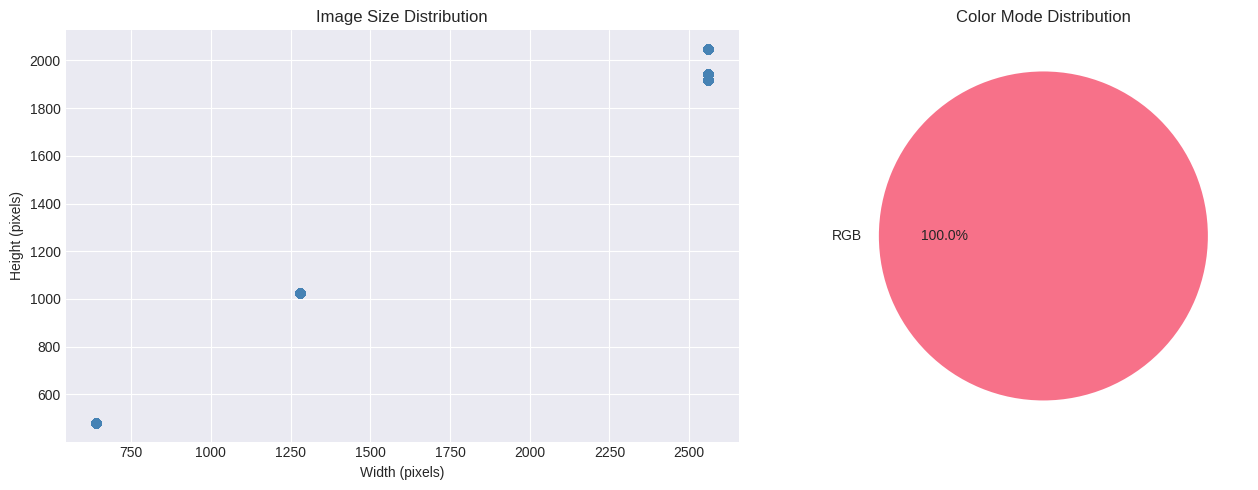

In [6]:
# Visualize image size distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Width vs Height scatter
axes[0].scatter(df_sizes['width'], df_sizes['height'], alpha=0.5, c='steelblue')
axes[0].set_xlabel('Width (pixels)')
axes[0].set_ylabel('Height (pixels)')
axes[0].set_title('Image Size Distribution')

# Size statistics
print("Image size statistics:")
print(f"  Width:  min={df_sizes['width'].min()}, max={df_sizes['width'].max()}, median={df_sizes['width'].median():.0f}")
print(f"  Height: min={df_sizes['height'].min()}, max={df_sizes['height'].max()}, median={df_sizes['height'].median():.0f}")

# Mode distribution
mode_counts = df_sizes['mode'].value_counts()
axes[1].pie(mode_counts.values, labels=mode_counts.index, autopct='%1.1f%%')
axes[1].set_title('Color Mode Distribution')

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/quality_image_sizes.png", dpi=150)
plt.show()

## 6. Check Split Integrity

In [7]:
# Verify split counts match expected
actual_counts = df_all['split'].value_counts().to_dict()
expected_counts = split_meta['counts']

print("Split verification:")
all_match = True
for split in ['train', 'val', 'test']:
    actual = actual_counts.get(split, 0)
    expected = expected_counts[split]
    match = actual == expected
    status = "✓" if match else "✗"
    print(f"  {split}: actual={actual}, expected={expected} {status}")
    if not match:
        all_match = False

if all_match:
    print("\n✓ All split counts match!")
else:
    print("\n✗ Split counts do not match!")

Split verification:
  train: actual=3964, expected=4487 ✗
  val: actual=913, expected=955 ✗
  test: actual=942, expected=981 ✗

✗ Split counts do not match!


In [8]:
# Verify family distribution per split
print("Family distribution verification:")

family_ok = True
for family in label_mapping['families'].keys():
    print(f"\n{family}:")
    for split in ['train', 'val', 'test']:
        actual = len(df_all[(df_all['family'] == family) & (df_all['split'] == split)])
        expected = split_meta['per_family'][family][split]
        match = actual == expected
        status = "✓" if match else "✗"
        print(f"  {split}: actual={actual}, expected={expected} {status}")
        if not match:
            family_ok = False

if family_ok:
    print("\n✓ All family distributions match!")
else:
    print("\n✗ Some family distributions do not match!")

Family distribution verification:

Cupressaceae:
  train: actual=1875, expected=2398 ✗
  val: actual=468, expected=510 ✗
  test: actual=486, expected=525 ✗

Pinaceae:
  train: actual=1666, expected=1666 ✓
  val: actual=355, expected=355 ✓
  test: actual=364, expected=364 ✓

Podocarpaceae:
  train: actual=217, expected=217 ✓
  val: actual=46, expected=46 ✓
  test: actual=47, expected=47 ✓

Taxaceae:
  train: actual=206, expected=206 ✓
  val: actual=44, expected=44 ✓
  test: actual=45, expected=45 ✓

✗ Some family distributions do not match!


## 7. Check for Duplicate Images

In [9]:
# Check for duplicate filenames across species
duplicates = df_all.groupby('filename')['path'].apply(lambda x: list(x)).to_dict()
duplicates = {k: v for k, v in duplicates.items() if len(v) > 1}

print(f"Duplicate filenames found: {len(duplicates)}")

if duplicates:
    print("\nDuplicates details:")
    for filename, paths in list(duplicates.items())[:5]:  # Show first 5
        print(f"  {filename}:")
        for p in paths:
            print(f"    - {p}")
    if len(duplicates) > 5:
        print(f"  ... and {len(duplicates) - 5} more")

Duplicate filenames found: 167

Duplicates details:
  10.png:
    - ../../data/split/train/Cupressaceae/Cunninghamia lanceolata/10.png
    - ../../data/split/train/Cupressaceae/Callitris columellaris/10.png
    - ../../data/split/val/Cupressaceae/Cunninghamia lanceolata/10.png
    - ../../data/split/test/Cupressaceae/Cunninghamia lanceolata/10.png
  11.png:
    - ../../data/split/train/Cupressaceae/Cunninghamia lanceolata/11.png
    - ../../data/split/train/Cupressaceae/Callitris columellaris/11.png
    - ../../data/split/val/Cupressaceae/Cunninghamia lanceolata/11.png
    - ../../data/split/val/Cupressaceae/Callitris columellaris/11.png
  110.png:
    - ../../data/split/train/Cupressaceae/Cunninghamia lanceolata/110.png
    - ../../data/split/train/Cupressaceae/Callitris columellaris/110.png
    - ../../data/split/test/Cupressaceae/Cunninghamia lanceolata/110.png
  1100.png:
    - ../../data/split/train/Cupressaceae/Callitris columellaris/1100.png
    - ../../data/split/test/Cupressac

Potential duplicate content (same species + file size): 247


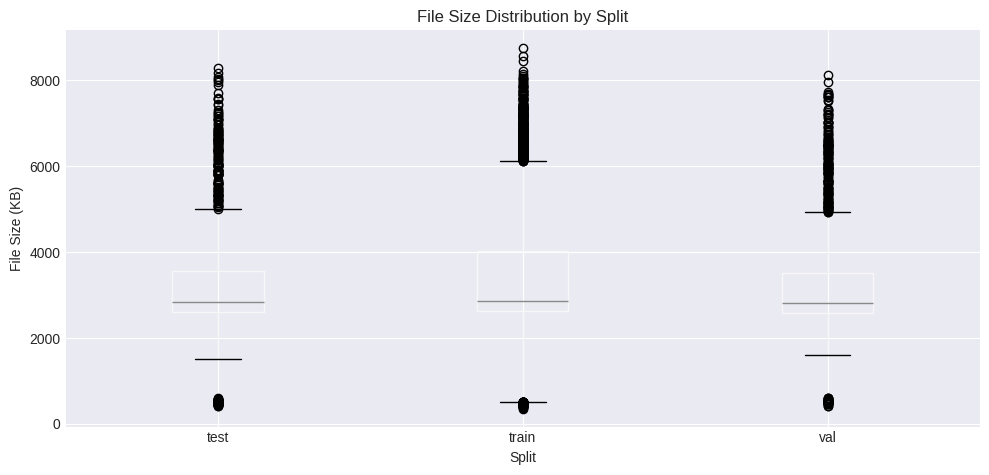

In [10]:
# Check for images with identical content (by file size)
def get_file_size(path):
    return os.path.getsize(path)

df_all['file_size'] = df_all['path'].apply(get_file_size)

# Find images with same size in same species
size_duplicates = df_all.groupby(['species', 'file_size'])['path'].apply(list)
size_duplicates = size_duplicates[size_duplicates.apply(len) > 1]

print(f"Potential duplicate content (same species + file size): {len(size_duplicates)}")

# Show distribution of file sizes
fig, ax = plt.subplots(figsize=(10, 5))
df_all['file_size_kb'] = df_all['file_size'] / 1024
df_all.boxplot(column='file_size_kb', by='split', ax=ax)
ax.set_xlabel('Split')
ax.set_ylabel('File Size (KB)')
ax.set_title('File Size Distribution by Split')
plt.suptitle('')
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/quality_file_sizes.png", dpi=150)
plt.show()

## 8. Check Symlinks

In [11]:
# Verify symlinks are valid
def check_symlink(path):
    p = Path(path)
    if not p.is_symlink():
        return False, "Not a symlink"
    if not p.exists():
        return False, "Broken symlink"
    target = p.resolve()
    if not target.exists():
        return False, "Target does not exist"
    return True, str(target)

print("Checking symlinks...")
broken_links = []
valid_links = 0

for idx, row in df_all.iterrows():
    if row['is_link']:
        is_valid, info = check_symlink(row['path'])
        if is_valid:
            valid_links += 1
        else:
            broken_links.append({'path': row['path'], 'issue': info})

print(f"Valid symlinks: {valid_links}")
print(f"Broken symlinks: {len(broken_links)}")

if broken_links:
    print("\nBroken symlinks:")
    for link in broken_links:
        print(f"  - {link['path']}: {link['issue']}")

Checking symlinks...
Valid symlinks: 5819
Broken symlinks: 0


## 9. Summary Report

In [12]:
# Generate quality assurance summary
qa_summary = {
    'total_images': len(df_all),
    'corrupted_images': len(df_corrupted),
    'broken_symlinks': len(broken_links),
    'duplicate_filenames': len(duplicates),
    'valid_symlinks': valid_links,
    'image_sizes': {
        'min_width': int(df_sizes['width'].min()),
        'max_width': int(df_sizes['width'].max()),
        'min_height': int(df_sizes['height'].min()),
        'max_height': int(df_sizes['height'].max()),
        'median_width': float(df_sizes['width'].median()),
        'median_height': float(df_sizes['height'].median())
    },
    'color_modes': df_sizes['mode'].value_counts().to_dict(),
    'split_counts': df_all['split'].value_counts().to_dict(),
    'all_checks_passed': (
        len(df_corrupted) == 0 and 
        len(broken_links) == 0 and 
        all_match and 
        family_ok
    )
}

with open(f"{OUTPUT_DIR}/qa_summary.json", 'w') as f:
    json.dump(qa_summary, f, indent=2)

print("=" * 60)
print("Quality Assurance Summary")
print("=" * 60)
print(f"\nTotal images: {qa_summary['total_images']}")
print(f"Corrupted images: {qa_summary['corrupted_images']}")
print(f"Broken symlinks: {qa_summary['broken_symlinks']}")
print(f"Duplicate filenames: {qa_summary['duplicate_filenames']}")
print(f"\nImage size range: {qa_summary['image_sizes']['min_width']}-{qa_summary['image_sizes']['max_width']} x {qa_summary['image_sizes']['min_height']}-{qa_summary['image_sizes']['max_height']}")
print(f"Median size: {qa_summary['image_sizes']['median_width']:.0f} x {qa_summary['image_sizes']['median_height']:.0f}")
print(f"\nColor modes: {qa_summary['color_modes']}")
print(f"\nAll checks passed: {'✓ YES' if qa_summary['all_checks_passed'] else '✗ NO'}")

Quality Assurance Summary

Total images: 5819
Corrupted images: 0
Broken symlinks: 0
Duplicate filenames: 167

Image size range: 640-2560 x 480-2048
Median size: 2560 x 1944

Color modes: {'RGB': 5819}

All checks passed: ✗ NO


## 10. Export Cleaned Dataset Manifest

In [13]:
# Export cleaned dataset manifest (only valid images)
df_clean = df_all.copy()

# Add family_idx
df_clean['family_idx'] = df_clean['family'].map(label_mapping['families'])

# Remove corrupted entries if any
if len(df_corrupted) > 0:
    # This is just for tracking, actual removal would require manual intervention
    pass

# Save manifest
manifest_path = f"{OUTPUT_DIR}/dataset_manifest.csv"
df_clean.to_csv(manifest_path, index=False)
print(f"Dataset manifest saved to: {manifest_path}")
print(f"\nManifest columns: {list(df_clean.columns)}")
print(f"Total entries: {len(df_clean)}")

Dataset manifest saved to: ../../data/split/dataset_manifest.csv

Manifest columns: ['path', 'split', 'family', 'species', 'filename', 'is_link', 'file_size', 'file_size_kb', 'family_idx']
Total entries: 5819


In [14]:
print("\n" + "=" * 60)
print("Phase 0 Quality Assurance Complete!")
print("=" * 60)
print("\nOutputs created:")
print(f"  1. QA summary: {OUTPUT_DIR}/qa_summary.json")
print(f"  2. Dataset manifest: {OUTPUT_DIR}/dataset_manifest.csv")
print(f"  3. Visualizations:")
print(f"     - {OUTPUT_DIR}/quality_image_sizes.png")
print(f"     - {OUTPUT_DIR}/quality_file_sizes.png")
print("\nNext steps:")
print("  1. If any issues found, resolve them before proceeding")
print("  2. Proceed to Phase 1 (Core Implementation)")


Phase 0 Quality Assurance Complete!

Outputs created:
  1. QA summary: ../../data/split/qa_summary.json
  2. Dataset manifest: ../../data/split/dataset_manifest.csv
  3. Visualizations:
     - ../../data/split/quality_image_sizes.png
     - ../../data/split/quality_file_sizes.png

Next steps:
  1. If any issues found, resolve them before proceeding
  2. Proceed to Phase 1 (Core Implementation)
